# Internal flux on the native cubed-sphere mesh

Maps of the `internal_flux` field stored in LFRic restart files (`restart_*-lfric_atm_<time steps>.nc`) of the HD 209458b experiments, one panel per experiment with a shared colour scale, following `Cubed-Sphere-Plots.ipynb`.
Each cell of the cubed-sphere mesh is drawn as a polygon.

In [1]:
import math
import warnings

import cartopy.crs as ccrs
import iris
import matplotlib.pyplot as plt
import numpy as np
import paths
from aeolus.lfric import load_lfric_raw
from aeolus.plot import figsave, subplot_label_generator, tex2cf_units
from common import (
    EXPERIMENTS,
    GROUPS,
    Diag,
    align_cbar_with_axes,
    common_kw_plt,
)

warnings.filterwarnings("ignore")
iris.FUTURE.date_microseconds = True

In [2]:
import cartopy.crs as ccrs
from matplotlib.collections import LineCollection, PolyCollection


def _unwrap_lons(lons, ref):
    """Shift longitudes to be within 180 degrees of the reference longitude."""
    return ref + (lons - ref + 180) % 360 - 180


def get_face_nodes(obj, decimals=6):
    """
    Get node coordinates and face-node connectivity of a cubed-sphere mesh.

    Parameters
    ----------
    obj: iris.mesh.MeshXY or iris.cube.Cube
        Either a mesh, a cube located on mesh faces (UGRID output, e.g.
        lfric_initial.nc), or a cube with bounded latitude and longitude
        coordinates of the cells (XIOS non-UGRID output, e.g. lfric_diag_main*).
    decimals: int, optional
        Precision used to merge cell corners into nodes (in units of the
        sphere radius), if the connectivity is built from coordinate bounds.

    Returns
    -------
    node_lons, node_lats: (n_nodes,) arrays
    face_nodes: (n_faces, n_corners) array of node indices
    """
    mesh = getattr(obj, "mesh", obj)
    if mesh is not None and hasattr(mesh, "face_node_connectivity"):
        if getattr(obj, "location", "face") != "face":
            raise ValueError("Cube must be located on mesh faces.")
        face_nodes = mesh.face_node_connectivity.indices_by_location()
        if np.ma.is_masked(face_nodes):
            raise NotImplementedError("Faces with different numbers of nodes.")
        return (
            mesh.node_coords.node_x.points,
            mesh.node_coords.node_y.points,
            np.asarray(face_nodes),
        )
    # No mesh: use the cell corners stored as lat-lon coordinate bounds
    try:
        lon_coord = obj.coord("longitude")
        lat_coord = obj.coord("latitude")
    except (AttributeError, iris.exceptions.CoordinateNotFoundError):
        raise ValueError(
            "Need a mesh or a cube with latitude and longitude coordinates."
        )
    if not (lon_coord.has_bounds() and lat_coord.has_bounds()):
        raise ValueError("Latitude and longitude coordinates must have bounds.")
    corner_lons = lon_coord.bounds
    corner_lats = lat_coord.bounds
    # Merge identical corners into nodes, comparing them as points on the unit
    # sphere to avoid ambiguity of longitudes (wrap-around and poles)
    lam, phi = np.deg2rad(corner_lons.ravel()), np.deg2rad(corner_lats.ravel())
    xyz = np.column_stack([
        np.cos(phi) * np.cos(lam),
        np.cos(phi) * np.sin(lam),
        np.sin(phi),
    ])
    _, first, inverse = np.unique(
        np.round(xyz, decimals) + 0.0,  # + 0.0 turns -0.0 into 0.0
        axis=0,
        return_index=True,
        return_inverse=True,
    )
    face_nodes = inverse.reshape(corner_lons.shape)
    return corner_lons.ravel()[first], corner_lats.ravel()[first], face_nodes


def mesh_face_polygons(node_lons, node_lats, face_nodes, pole_tol=1e-6):
    """
    Get vertices of mesh faces as lon-lat polygons that do not wrap around.

    Polygons are unwrapped in longitude relative to their first vertex,
    and polygons touching a pole get the pole vertex split in two,
    so that they look right in a lon-lat (PlateCarree) space.

    Returns
    -------
    verts: list of (n_vertices, 2) arrays of (lon, lat)
    """
    lons = node_lons[face_nodes]
    lats = node_lats[face_nodes]
    at_pole = np.abs(np.abs(lats) - 90) < pole_tol
    # Unwrap relative to the first non-pole vertex of each face
    ref_idx = np.argmax(~at_pole, axis=1)
    ref = np.take_along_axis(lons, ref_idx[:, None], axis=1)
    lons = _unwrap_lons(lons, ref)

    verts = []
    n = lons.shape[1]
    for i in range(lons.shape[0]):
        if not at_pole[i].any():
            verts.append(np.column_stack([lons[i], lats[i]]))
            continue
        # Replace the pole vertex with two vertices at the longitudes of its neighbours
        poly = []
        for j in range(n):
            if at_pole[i, j]:
                poly.append((lons[i, (j - 1) % n], lats[i, j]))
                poly.append((lons[i, (j + 1) % n], lats[i, j]))
            else:
                poly.append((lons[i, j], lats[i, j]))
        verts.append(np.array(poly))
    return verts


def plot_mesh_polygons(cube, ax=None, transform="auto", edgecolor="none", **kwargs):
    """
    Plot cubed-sphere mesh data on faces as polygons in lon-lat coordinates.

    Parameters
    ----------
    cube: iris.cube.Cube
        1D cube of cell values (slice other dimensions beforehand), either
        on mesh faces or with bounded latitude and longitude coordinates.
    ax: matplotlib.axes.Axes, optional
        Axes to plot on (e.g. cartopy GeoAxes). Defaults to the current axes.
    transform: cartopy.crs.CRS, "auto" or None, optional
        Coordinate system of the lon-lat polygons.
        - "auto" (default): `ccrs.PlateCarree()` if `ax` is a cartopy GeoAxes,
          otherwise None.
        - None: plot on regular (non-cartopy) matplotlib axes, with longitude
          and latitude in degrees as x and y.
        - a cartopy CRS.
    edgecolor: str, optional
        Polygon edge colour.
    **kwargs:
        Passed to `matplotlib.collections.PolyCollection` (cmap, norm, etc).

    Returns
    -------
    matplotlib.collections.PolyCollection
    """
    if ax is None:
        ax = plt.gca()
    if isinstance(transform, str) and transform == "auto":
        transform = ccrs.PlateCarree() if hasattr(ax, "projection") else None
    if cube.ndim != 1:
        raise ValueError(f"Cube must be 1D, got shape {cube.shape}.")
    verts = mesh_face_polygons(*get_face_nodes(cube))
    data = cube.data
    if len(verts) != data.shape[0]:
        raise ValueError(
            f"{len(verts)} faces do not match {data.shape[0]} data points."
        )
    if transform is None:
        # Plain axes: duplicate polygons crossing the dateline, shifted by 360 degrees
        # (cartopy wraps them automatically, so this is not needed for GeoAxes)
        extra_verts, extra_idx = [], []
        for i, v in enumerate(verts):
            if v[:, 0].max() > 180:
                extra_verts.append(v - [360, 0])
                extra_idx.append(i)
            elif v[:, 0].min() < -180:
                extra_verts.append(v + [360, 0])
                extra_idx.append(i)
        verts = verts + extra_verts
        data = np.ma.concatenate([data, data[extra_idx]])
    else:
        kwargs["transform"] = transform
    coll = PolyCollection(verts, array=data, edgecolor=edgecolor, **kwargs)
    ax.add_collection(coll)
    if transform is None:
        ax.set_xlim(-180, 180)
        ax.set_ylim(-90, 90)
    return coll


def cube_panel_edges(obj):
    """
    Find the 12 edges of the six panels of a cubed-sphere mesh.

    The panel edges are traced along the mesh topology: they start at the
    8 cube corners (nodes shared by 3 faces instead of 4) and continue
    "straight" through each node to the next corner.

    Parameters
    ----------
    obj: iris.mesh.MeshXY or iris.cube.Cube
        Mesh or cube, see `get_face_nodes()`.

    Returns
    -------
    list of (n_points, 2) arrays of (lon, lat), unwrapped in longitude.
    """
    node_lons, node_lats, face_nodes = get_face_nodes(obj)
    n_corners = face_nodes.shape[1]

    # Map each (sorted) node pair to the faces sharing it, and each node to its neighbours
    edge_faces = {}
    for i_face, nodes in enumerate(face_nodes):
        for j in range(n_corners):
            key = tuple(sorted((nodes[j], nodes[(j + 1) % n_corners])))
            edge_faces.setdefault(key, set()).add(i_face)
    neighbours = {}
    for a, b in edge_faces:
        neighbours.setdefault(a, []).append(b)
        neighbours.setdefault(b, []).append(a)

    corners = [node for node, nbrs in neighbours.items() if len(nbrs) == 3]
    if len(corners) != 8:
        raise ValueError(f"Expected 8 cube corners, found {len(corners)}.")

    def _faces(a, b):
        return edge_faces[tuple(sorted((a, b)))]

    lines = []
    seen = set()
    for start in corners:
        for nxt in neighbours[start]:
            path = [start, nxt]
            # Walk straight on: the next edge shares no face with the previous one
            while len(neighbours[path[-1]]) != 3:
                prev, cur = path[-2], path[-1]
                (nxt,) = [
                    n
                    for n in neighbours[cur]
                    if n != prev and not (_faces(prev, cur) & _faces(cur, n))
                ]
                path.append(nxt)
            key = tuple(sorted((path[0], path[-1]))) + (path[1],)
            key_rev = tuple(sorted((path[0], path[-1]))) + (path[-2],)
            if key in seen or key_rev in seen:
                continue
            seen.add(key)
            lons = np.unwrap(node_lons[path], period=360)
            lines.append(np.column_stack([lons, node_lats[path]]))
    if len(lines) != 12:
        raise ValueError(f"Expected 12 panel edges, found {len(lines)}.")
    return lines


def plot_cube_panel_edges(
    obj, ax=None, transform="auto", color="k", linewidth=1, **kwargs
):
    """
    Plot the edges of the six panels of a cubed-sphere mesh as lines.

    Parameters
    ----------
    obj: iris.mesh.MeshXY or iris.cube.Cube
        Mesh or cube, see `get_face_nodes()`.
    ax: matplotlib.axes.Axes, optional
        Axes to plot on (e.g. cartopy GeoAxes). Defaults to the current axes.
    transform: cartopy.crs.CRS, "auto" or None, optional
        Coordinate system of the lon-lat lines.
        - "auto" (default): `ccrs.Geodetic()` (great circle arcs between mesh
          nodes) if `ax` is a cartopy GeoAxes, otherwise None.
        - None: plot on regular (non-cartopy) matplotlib axes, with longitude
          and latitude in degrees as x and y.
        - a cartopy CRS, e.g. `ccrs.PlateCarree()` for straight lines in lon-lat.
    color: str, optional
        Line colour.
    linewidth: float, optional
        Line width.
    **kwargs:
        Passed to `matplotlib.collections.LineCollection`.

    Returns
    -------
    matplotlib.collections.LineCollection
    """
    if ax is None:
        ax = plt.gca()
    if isinstance(transform, str) and transform == "auto":
        transform = ccrs.Geodetic() if hasattr(ax, "projection") else None
    lines = cube_panel_edges(obj)
    if transform is None:
        # Plain axes: duplicate lines crossing the dateline, shifted by 360 degrees
        # (cartopy wraps them automatically, so this is not needed for GeoAxes)
        lines = (
            lines
            + [ln - [360, 0] for ln in lines if ln[:, 0].max() > 180]
            + [ln + [360, 0] for ln in lines if ln[:, 0].min() < -180]
        )
    else:
        kwargs["transform"] = transform
    coll = LineCollection(lines, colors=color, linewidths=linewidth, **kwargs)
    ax.add_collection(coll)
    if transform is None:
        ax.set_xlim(-180, 180)
        ax.set_ylim(-90, 90)
    return coll

## Parameters

In [3]:
GROUP_KEY = "hd209_all"
# Subset of the group's simulations to plot (all of them if None)
CASES = None
N_STEPS = 28800  # number of elapsed time steps in the restart file name
NCOLS = 3  # number of panels per row
SHOW_PANEL_EDGES = True  # overlay the edges of the six cubed-sphere panels
MAP_PROJ = ccrs.PlateCarree(central_longitude=0)
SAVE_FIGS = True

EXPS = list(GROUPS[GROUP_KEY].simulations) if CASES is None else CASES
print(*EXPS, sep="\n")

hd209_dt30_nrad4
hd209_rand_t100k_nf20_tau1e5_amp1e-2_sclht6


## Load the restart files

Restart files are looked up in `<group>/<label>/restarts/` and then in `<group>/<label>/`; experiments without a restart file for `N_STEPS` are skipped.

In [4]:
def find_restart(exp_key, n_steps=N_STEPS):
    """Path to the restart file of an experiment after `n_steps` time steps, or None."""
    exp_dir = (
        paths.data_work
        / "lfric"
        / EXPERIMENTS[exp_key].group
        / EXPERIMENTS[exp_key].label
    )
    for subdir in [exp_dir / "restarts", exp_dir]:
        fnames = sorted(subdir.glob(f"restart_*-lfric_atm_{n_steps:010d}.nc"))
        if fnames:
            if len(fnames) > 1:
                print(f"[{exp_key}] several restart files, using {fnames[0].name}")
            return fnames[0]
    return None


cubes = {}
for exp_key in EXPS:
    fname = find_restart(exp_key)
    if fname is None:
        print(f"[{exp_key}] no restart file for {N_STEPS} time steps, skipping")
        continue
    cube = load_lfric_raw(fname).extract_cube("internal_flux")
    if cube.units.is_unknown():
        cube.units = "W m-2"
    cubes[exp_key] = cube
    print(
        f"[{exp_key}] {fname.relative_to(paths.data_work)}\n"
        f"    min = {float(cube.data.min()):.3f}, max = {float(cube.data.max()):.3f}, "
        f"mean (unweighted) = {float(cube.data.mean()):.3f} [{cube.units}]"
    )
PLOT_EXPS = list(cubes)
assert PLOT_EXPS, f"No restart files found for {N_STEPS} time steps"

# Model time of the restart files
DAYS = {k: N_STEPS * EXPERIMENTS[k].timestep / 86400 for k in PLOT_EXPS}
if len(set(DAYS.values())) == 1:
    TIME_STR = f"day {next(iter(DAYS.values())):g}"
else:
    TIME_STR = f"{N_STEPS} time steps"
print(TIME_STR)

[hd209_dt30_nrad4] lfric/hd209/dt30_nrad4/restarts/restart_hd209-lfric_atm_0000028800.nc
    min = 5.670, max = 5.670, mean (unweighted) = 5.670 [W m-2]
[hd209_rand_t100k_nf20_tau1e5_amp1e-2_sclht6] lfric/hd209_rand/rand_t100k_nf20_tau1e5_amp1e-2_sclht6/restarts/restart_hd209_rand-lfric_atm_0000028800.nc
    min = -18.840, max = 19.593, mean (unweighted) = 0.004 [W m-2]
day 10


## Maps

In [5]:
def exp_title(exp_key):
    """Experiment title, or its label if the titles in `PLOT_EXPS` are not unique."""
    titles = [EXPERIMENTS[k].title for k in PLOT_EXPS]
    if len(set(titles)) < len(titles):
        return EXPERIMENTS[exp_key].label
    return EXPERIMENTS[exp_key].title


def plot_internal_flux_maps(
    cubes, show_panel_edges=SHOW_PANEL_EDGES, ncol=NCOLS, add_cbar=True
):
    """Plot `internal_flux` on the native mesh for each experiment in `cubes`."""
    exps = list(cubes)
    all_data = np.ma.concatenate([c.data for c in cubes.values()])
    # Diverging colour map centred on 0 if the flux changes sign
    cnorm = float(all_data.min()) < 0 < float(all_data.max())
    diag = Diag(
        title="Internal Flux",
        units="$W$ $m^{-2}$",
        recipe=None,
        cnorm=cnorm,
        kw_plt={"cmap": "RdBu_r" if cnorm else "inferno"},
    )
    for cube in cubes.values():
        cube.convert_units(tex2cf_units(diag.units))
    kw_plt, levels = common_kw_plt(diag, list(cubes.values()))
    if kw_plt["norm"].vmin == kw_plt["norm"].vmax:
        # Uniform flux: widen the colour range so the colour bar can be drawn
        vmid = kw_plt["norm"].vmin
        kw_plt["norm"].vmin, kw_plt["norm"].vmax = vmid - 1, vmid + 1
        levels = None

    ncols = min(ncol, len(exps))
    nrows = math.ceil(len(exps) / ncols)
    # Maps in rows of `ncols` (empty cells are "."), and a colour bar spanning all rows
    mosaic = [list(exps[i : i + ncols]) for i in range(0, len(exps), ncols)]
    mosaic[-1] += ["."] * (ncols - len(mosaic[-1]))
    if add_cbar:
        mosaic = [row + ["cbar"] for row in mosaic]
    fig = plt.figure(figsize=(3.5 * ncols, 2 * nrows + 0.5), layout="compressed")
    axd = fig.subplot_mosaic(
        mosaic,
        width_ratios=[1] * ncols + ([0.03] if add_cbar else []),
        per_subplot_kw={tuple(exps): {"projection": MAP_PROJ}},
    )

    iletters = subplot_label_generator()
    for i, (exp_key, cube) in enumerate(cubes.items()):
        ax = axd[exp_key]
        ax.set_title(f"({next(iletters)})", loc="left", fontsize="medium")
        ax.set_title(
            exp_title(exp_key),
            fontsize="medium",
            color=EXPERIMENTS[exp_key].kw_plt.get("color", "k"),
        )
        ax.set_global()
        im = plot_mesh_polygons(cube, ax=ax, antialiased=False, **kw_plt)
        if show_panel_edges:
            plot_cube_panel_edges(cube, ax=ax, linewidth=0.5)
        int_flux = EXPERIMENTS[exp_key].internal_flux
        if int_flux is not None and int_flux.method == "uniform":
            # Label uniform internal flux in the middle of the map
            ax.text(
                0.5,
                0.5,
                f"constant {int_flux.value:.3f} W m$^{{-2}}$",
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize="medium",
                bbox={"facecolor": "w", "edgecolor": "none", "alpha": 0.8},
            )
        ax.gridlines(
            draw_labels=["bottom", "left"] if i % ncols == 0 else ["bottom"],
            xlocs=np.arange(-180, 181, 60),
            ylocs=np.arange(-90, 91, 30),
            linestyle="--",
            alpha=0.5,
            xlabel_style={"size": "x-small"},
            ylabel_style={"size": "x-small"},
        )
    if add_cbar:
        cbar = fig.colorbar(
            im, cax=axd["cbar"], orientation="vertical", extend="both", ticks=levels
        )

    fig.suptitle(
        GROUPS[GROUP_KEY].title
        + "\n"
        + " | ".join([f"{diag.title} [{diag.units}]", TIME_STR]),
        fontsize="medium",
    )
    if add_cbar:
        # Freeze the layout and make the colour bar as tall as the maps
        align_cbar_with_axes(cbar, [axd[exp_key] for exp_key in exps])

    if SAVE_FIGS:
        figsave(
            fig,
            paths.drafts / "xsec" / f"{GROUP_KEY}__internal_flux__cs__steps_{N_STEPS}",
        )
    return fig

Saved to ../figures/drafts/xsec/hd209_all__internal_flux__cs__steps_28800.pdf
Size: 96.9 KB


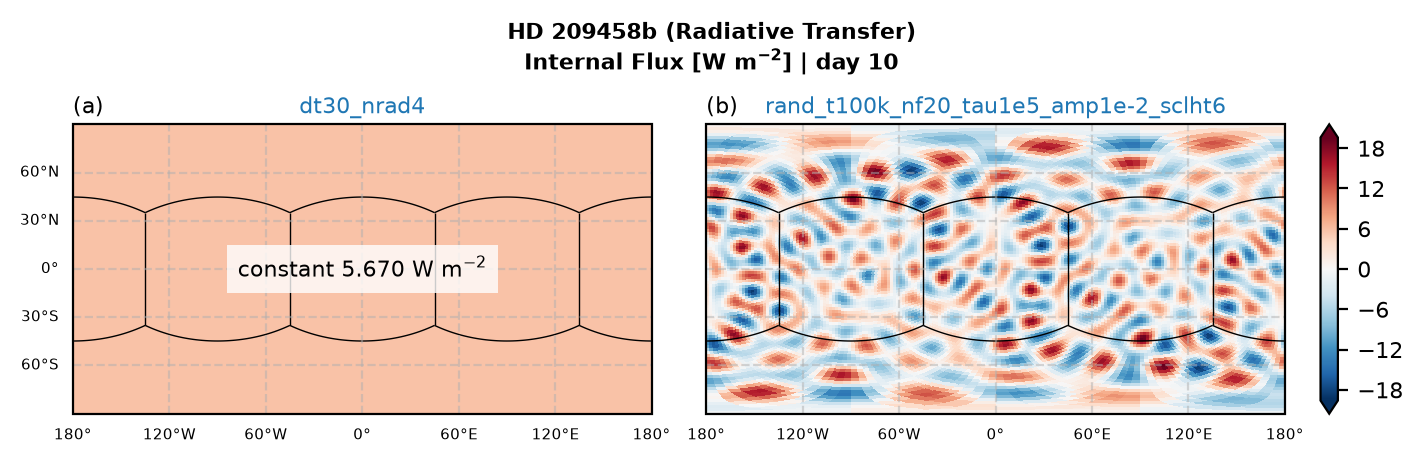

In [6]:
plot_internal_flux_maps(cubes);